# 使用 Google Colab GPU 訓練神經網路：MNIST 手寫數字分類

本 Notebook 依據知乎文章〈完整的動手指南，可在 Google Colab GPU 上訓練你的神經網絡模型〉整理與實作。

## 學習目標
1. 理解 CPU 與 GPU 在平行運算上的差異。
2. 使用 PyTorch / TorchVision 載入 MNIST。
3. 將資料與模型移至可用的運算裝置（CUDA GPU 或 CPU）。
4. 建立簡單的全連接神經網路，完成訓練與驗證。
5. 觀察訓練損失、驗證損失與準確率。

> **執行環境**：建議使用 Google Colab，並在「執行階段 → 變更執行階段類型」選擇 GPU。若沒有 GPU，程式會自動使用 CPU。Colab 可用 GPU 型號、免費額度與連線時間會依 Google 當下政策及資源供應而變動，並非固定保證。
>
> **與原文的差異**：原文部分程式碼在 PDF 中未完整呈現，且部分函式未提供完整定義。本 Notebook 依文章所述流程補齊必要程式，並加入 `model.train()`、`model.eval()`、`torch.no_grad()`、梯度清零順序及可重現的隨機種子等實務處理。

## 1. GPU 與 CPU 的角色

文章指出，神經網路常見的矩陣乘法與大量重複運算，適合由 GPU 的大量運算核心平行處理。GPU 通常具有較高的記憶體頻寬，因此在合適的深度學習工作負載上，可能比 CPU 更有效率。

但 GPU 並非在所有工作上都能取代 CPU：CPU 仍負責程式控制、資料準備及其他一般用途工作，GPU 則協助執行大量平行計算。實際效能仍取決於模型、資料量、硬體與資料傳輸成本。

## 2. 設定執行環境與匯入套件

在 Google Colab 中，建議先選擇 GPU 執行階段。接著匯入 PyTorch、TorchVision、NumPy 與 Matplotlib。

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

plt.rcParams["figure.facecolor"] = "white"

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. 下載 MNIST 並切分訓練集、驗證集

MNIST 是手寫數字影像資料集，每張影像大小為 28 × 28，分類標籤為 0 至 9。依照文章的設定，保留 10,000 筆作為驗證集，其餘資料用於訓練。

In [2]:
dataset = MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

val_size = 10_000
train_size = len(dataset) - val_size

split_generator = torch.Generator().manual_seed(SEED)
train_set, val_set = random_split(
    dataset,
    [train_size, val_size],
    generator=split_generator
)

print(f"完整資料集：{len(dataset):,} 筆")
print(f"訓練集：{len(train_set):,} 筆")
print(f"驗證集：{len(val_set):,} 筆")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 486kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.25MB/s]

完整資料集：60,000 筆
訓練集：50,000 筆
驗證集：10,000 筆


## 4. 建立 DataLoader

DataLoader 以批次方式提供資料。文章示範訓練批次大小為 128、驗證批次大小為 256。`pin_memory=True` 在使用 CUDA 時可能加快 CPU 到 GPU 的資料傳輸；在 CPU 環境則關閉。

In [3]:
batch_size = 128
val_batch_size = 256
pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=pin_memory
)
val_loader = DataLoader(
    val_set,
    batch_size=val_batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=pin_memory
)

images, labels = next(iter(train_loader))
print("影像批次形狀：", images.shape)
print("標籤批次形狀：", labels.shape)

影像批次形狀： torch.Size([128, 1, 28, 28])
標籤批次形狀： torch.Size([128])


## 5. 建立 MNIST 全連接神經網路

模型結構與文章一致：輸入層 784 個特徵（28 × 28 攤平）、一層 32 個神經元的隱藏層、ReLU 啟用函數，以及 10 個輸出類別。輸出為 logits，搭配 `cross_entropy` 計算分類損失。

In [4]:
class MnistModel(nn.Module):
    def __init__(self, input_size=784, hidden_size=32, num_classes=10):
        super().__init__()
        self.linear1 = nn.Linear(input_size, hidden_size)
        self.linear2 = nn.Linear(hidden_size, num_classes)

    def forward(self, xb):
        xb = xb.view(xb.size(0), -1)  # [batch, 1, 28, 28] -> [batch, 784]
        hidden = F.relu(self.linear1(xb))
        return self.linear2(hidden)  # logits

    def training_step(self, batch):
        images, labels = batch
        logits = self(images)
        return F.cross_entropy(logits, labels)

    def validation_step(self, batch):
        images, labels = batch
        logits = self(images)
        loss = F.cross_entropy(logits, labels)
        acc = (logits.argmax(dim=1) == labels).float().mean()
        return {"val_loss": loss.detach(), "val_acc": acc.detach()}

    def validation_epoch_end(self, outputs):
        losses = torch.stack([x["val_loss"] for x in outputs])
        accuracies = torch.stack([x["val_acc"] for x in outputs])
        return {
            "val_loss": losses.mean().item(),
            "val_acc": accuracies.mean().item()
        }

## 6. 選擇運算裝置

若 CUDA 可用，使用 GPU；否則使用 CPU。這讓同一份程式可以在不同硬體環境中執行。

In [5]:
def get_default_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

device = get_default_device()
print("目前使用的裝置：", device)

目前使用的裝置： cuda


## 7. 將資料或模型移至指定裝置

文章以輔助函式處理 Tensor 與 tuple/list。本實作也支援 dictionary，方便在批次資料結構改變時使用。

In [6]:
def to_device(data, device):
    if isinstance(data, (list, tuple)):
        return [to_device(x, device) for x in data]
    if isinstance(data, dict):
        return {key: to_device(value, device) for key, value in data.items()}
    if torch.is_tensor(data):
        return data.to(device, non_blocking=True)
    return data

## 8. 建立 DeviceDataLoader

這個包裝器會在每個批次被取出時，將資料移至指定裝置，避免在訓練迴圈中重複撰寫搬移程式。

In [7]:
class DeviceDataLoader:
    def __init__(self, dataloader, device):
        self.dataloader = dataloader
        self.device = device

    def __iter__(self):
        for batch in self.dataloader:
            yield to_device(batch, self.device)

    def __len__(self):
        return len(self.dataloader)

train_loader = DeviceDataLoader(train_loader, device)
val_loader = DeviceDataLoader(val_loader, device)

## 9. 定義驗證與訓練函式

每個 epoch 先進行訓練，再以驗證集評估。訓練時呼叫 `model.train()`；驗證時呼叫 `model.eval()` 並使用 `torch.no_grad()`，避免計算驗證階段不需要的梯度。

In [8]:
@torch.no_grad()
def evaluate(model, val_loader):
    model.eval()
    outputs = [model.validation_step(batch) for batch in val_loader]
    return model.validation_epoch_end(outputs)


def fit(epochs, lr, model, train_loader, val_loader,
        opt_func=torch.optim.SGD):
    history = []
    optimizer = opt_func(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        running_loss = []

        for batch in train_loader:
            loss = model.training_step(batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            running_loss.append(loss.detach().item())

        val_result = evaluate(model, val_loader)
        train_loss = float(np.mean(running_loss))
        record = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            **val_result
        }
        history.append(record)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"train_loss: {train_loss:.4f} | "
            f"val_loss: {val_result['val_loss']:.4f} | "
            f"val_acc: {val_result['val_acc']:.4f}"
        )

    return history

## 10. 建立模型並移至 GPU / CPU

模型與輸入資料必須位於相同裝置，否則 PyTorch 會因裝置不一致而發生錯誤。

In [12]:
num_classes = 10
model = MnistModel(input_size=784, hidden_size=32, num_classes=num_classes)
# 直接使用 PyTorch 內建的 .to(device) 方法將模型移至指定裝置
model.to(device)

print(model)
print("模型參數所在裝置：", next(model.parameters()).device)

MnistModel(
  (linear1): Linear(in_features=784, out_features=32, bias=True)
  (linear2): Linear(in_features=32, out_features=10, bias=True)
)
模型參數所在裝置： cuda:0


## 11. 訓練、驗證與結果視覺化

文章示範以 MNIST 進行分類。以下設定訓練 5 個 epoch、學習率 0.1，使用 SGD。訓練時間會依 CPU/GPU 型號、Colab 資源及執行環境而異。

In [13]:
epochs = 5
learning_rate = 0.1

history = fit(
    epochs=epochs,
    lr=learning_rate,
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    opt_func=torch.optim.SGD
)

Epoch [1/5] train_loss: 0.6345 | val_loss: 0.3602 | val_acc: 0.8979
Epoch [2/5] train_loss: 0.3197 | val_loss: 0.3213 | val_acc: 0.9113
Epoch [3/5] train_loss: 0.2758 | val_loss: 0.2741 | val_acc: 0.9229
Epoch [4/5] train_loss: 0.2441 | val_loss: 0.2502 | val_acc: 0.9280
Epoch [5/5] train_loss: 0.2209 | val_loss: 0.2296 | val_acc: 0.9332


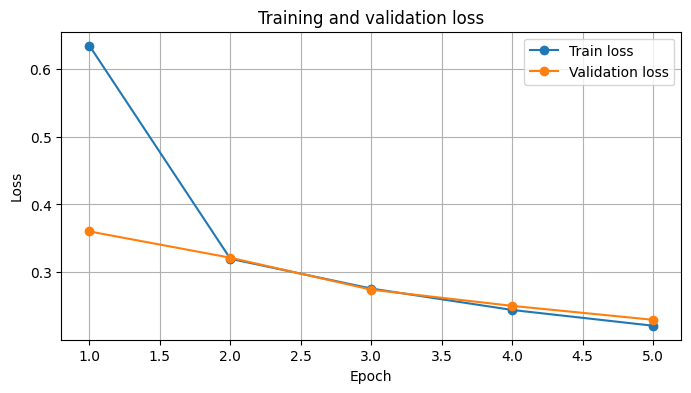

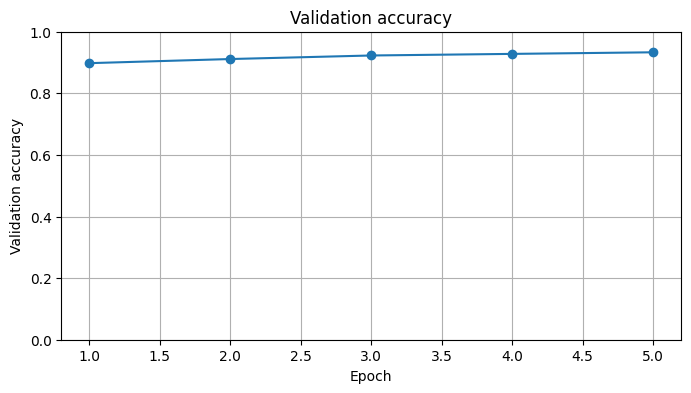

最後一個 epoch 的驗證準確率：93.32%


In [14]:
epochs_axis = [item["epoch"] for item in history]
train_losses = [item["train_loss"] for item in history]
val_losses = [item["val_loss"] for item in history]
val_accuracies = [item["val_acc"] for item in history]

plt.figure(figsize=(8, 4))
plt.plot(epochs_axis, train_losses, marker="o", label="Train loss")
plt.plot(epochs_axis, val_losses, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs_axis, val_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

print(f"最後一個 epoch 的驗證準確率：{val_accuracies[-1] * 100:.2f}%")

## 12. 查看部分預測結果

顯示數張驗證資料及模型預測，直觀檢查分類結果。

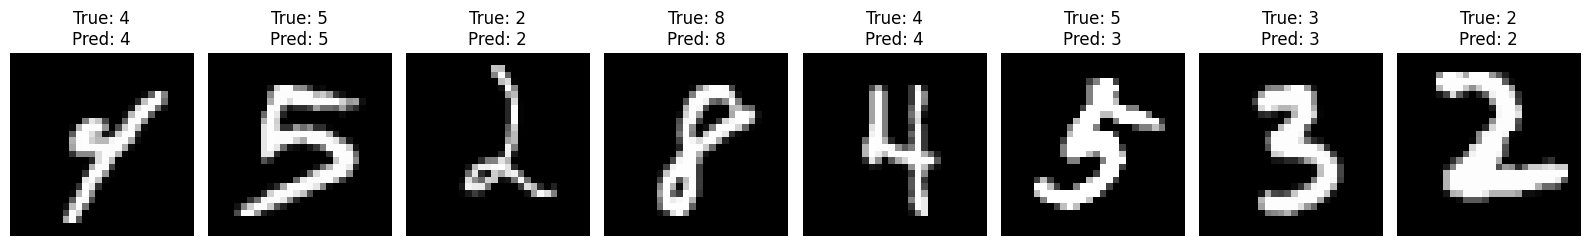

In [15]:
@torch.no_grad()
def show_predictions(model, dataset, device, n=8):
    model.eval()
    n = min(n, len(dataset))
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.5))
    if n == 1:
        axes = [axes]

    for i in range(n):
        image, label = dataset[i]
        logits = model(image.unsqueeze(0).to(device))
        prediction = logits.argmax(dim=1).item()

        axes[i].imshow(image.squeeze(0), cmap="gray")
        axes[i].set_title(f"True: {label}\nPred: {prediction}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(model, val_set, device, n=8)

## 13. 儲存模型權重（選用）

若要在之後載入模型，可以儲存 `state_dict`。載入時需建立相同架構的模型。

In [16]:
model_path = "mnist_mlp.pth"
torch.save(model.state_dict(), model_path)
print(f"模型權重已儲存至：{model_path}")

# 載入範例：
# loaded_model = MnistModel(input_size=784, hidden_size=32, num_classes=10)
# loaded_model.load_state_dict(torch.load(model_path, map_location=device))
# loaded_model = loaded_model.to(device)
# loaded_model.eval()

模型權重已儲存至：mnist_mlp.pth


### 13.1. 將模型儲存至 Google 雲端硬碟 (Google Drive)
執行以下儲存前，Colab 會彈出視窗請求存取您的 Google 雲端硬碟權限，請點選「連線到 Google 雲端硬碟」並允許存取。

In [17]:
from google.colab import drive
import os

# 1. 掛載 Google Drive
drive.mount('/content/drive')

# 2. 定義雲端硬碟中的儲存資料夾與檔名
# 預設會儲存在您雲端硬碟根目錄下的 'colab_models' 資料夾中
drive_save_dir = '/content/drive/MyDrive/colab_models'
os.makedirs(drive_save_dir, exist_ok=True)

drive_model_path = os.path.join(drive_save_dir, 'mnist_mlp.pth')

# 3. 儲存模型權重
torch.save(model.state_dict(), drive_model_path)
print(f"模型權重已成功直接儲存至您的 Google 雲端硬碟：{drive_model_path}")

Mounted at /content/drive
模型權重已成功直接儲存至您的 Google 雲端硬碟：/content/drive/MyDrive/colab_models/mnist_mlp.pth


## 14. 結論與延伸

本實作展示了以 PyTorch 在可用 GPU 上訓練神經網路的基本流程：設定運算裝置、載入資料、建立 DataLoader、定義模型、將模型與資料移至相同裝置、訓練並驗證。

文章結尾另提到 SLIDE（Sub-Linear Deep Learning Engine），其核心方向是減少反向傳播中的部分不必要計算，並探索以 CPU 訓練深度學習模型的可能性。

### 注意事項
- GPU 是否可用以 `torch.cuda.is_available()` 的實際結果為準。
- GPU 不一定對所有模型都更快；小型模型可能受資料傳輸與啟動成本影響。
- 本 Notebook 的準確率需以實際執行結果為準，不預先保證特定數值。
- 本實作是入門用 MLP，不是 VGG16 等大型 CNN 模型。

## 參考資料
- 安大叔，〈完整的動手指南，可在 Google Colab GPU 上訓練你的神經網絡模型〉，知乎專欄，2021-06-09。  
  https://zhuanlan.zhihu.com/p/379291795
- PyTorch 官方文件：https://pytorch.org/docs/stable/index.html
- TorchVision 官方文件：https://pytorch.org/vision/stable/index.html
